In [ ]:
import numpy as np
import pandas as pd
import soundfile as sf
import tempfile
from pathlib import Path
from datasets import load_from_disk
import sys
import soundfile as sf
from datasets import Audio
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import librosa
import librosa.display

In [ ]:
DATA_DIR = Path("data/raw/kathbath")

languages = ["hindi", "tamil", "telugu"]

datasets = {}

for language in languages:
    path = DATA_DIR / language / "train"
    datasets[language] = load_from_disk(str(path))
    print(language, len(datasets[language]))

Loading dataset from disk:   0%|          | 0/34 [00:00<?, ?it/s]

hindi 91752


Loading dataset from disk:   0%|          | 0/43 [00:00<?, ?it/s]

tamil 95762


Loading dataset from disk:   0%|          | 0/35 [00:00<?, ?it/s]

telugu 70673


In [ ]:
preprocess_path = Path("../../himanshu/milestone-2")

sys.path.insert(0, str(preprocess_path.resolve()))

from preprocess import preprocess

print("Shared preprocessing function imported successfully.")

Shared preprocessing function imported successfully.


In [ ]:
speaker_metadata = {}

for language in ["hindi", "tamil", "telugu"]:
    meta = datasets[language].select_columns(
        ["speaker_id", "gender"]
    ).to_pandas()

    # Check whether any speaker has multiple gender labels
    gender_counts = meta.groupby("speaker_id")["gender"].nunique()

    inconsistent = (gender_counts > 1).sum()

    assert inconsistent == 0, (
    f"Inconsistent gender labels found in {language}"
    )

    # One row per speaker
    speakers = meta.drop_duplicates(
        subset=["speaker_id", "gender"]
    ).copy()

    speaker_metadata[language] = speakers

    print(f"\n{language.upper()}")
    print("Unique speakers:", speakers["speaker_id"].nunique())
    print("Speakers with inconsistent gender:", inconsistent)
    print("\nSpeaker gender distribution:")
    print(speakers["gender"].value_counts(dropna=False))


HINDI
Unique speakers: 101
Speakers with inconsistent gender: 0

Speaker gender distribution:
gender
Female    53
Male      48
Name: count, dtype: int64

TAMIL
Unique speakers: 138
Speakers with inconsistent gender: 0

Speaker gender distribution:
gender
Male      106
Female     32
Name: count, dtype: int64

TELUGU
Unique speakers: 84
Speakers with inconsistent gender: 0

Speaker gender distribution:
gender
Male      43
Female    41
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

SEED = 42
split_mappings = {}

for language, speakers in speaker_metadata.items():

    # 70% train, 30% temporary
    train_speakers, temp_speakers = train_test_split(
        speakers,
        test_size=0.30,
        random_state=SEED,
        stratify=speakers["gender"]
    )

    # Divide remaining 30% equally into validation and test
    val_speakers, test_speakers = train_test_split(
        temp_speakers,
        test_size=0.50,
        random_state=SEED,
        stratify=temp_speakers["gender"]
    )

    mapping = {}

    for speaker_id in train_speakers["speaker_id"]:
        mapping[speaker_id] = "train"

    for speaker_id in val_speakers["speaker_id"]:
        mapping[speaker_id] = "validation"

    for speaker_id in test_speakers["speaker_id"]:
        mapping[speaker_id] = "test"

    split_mappings[language] = mapping

    print(f"\n{language.upper()}")
    print("Train:", len(train_speakers))
    print("Validation:", len(val_speakers))
    print("Test:", len(test_speakers))


HINDI
Train: 70
Validation: 15
Test: 16

TAMIL
Train: 96
Validation: 21
Test: 21

TELUGU
Train: 58
Validation: 13
Test: 13


In [29]:
for language, speakers in speaker_metadata.items():

    result = speakers.copy()
    result["split"] = result["speaker_id"].map(
        split_mappings[language]
    )

    print(f"\n{language.upper()}")
    print(pd.crosstab(result["split"], result["gender"]))

    # Every speaker must belong to exactly one split
    assert result["split"].notna().all()
    assert result["speaker_id"].is_unique
    assert len(result) == len(split_mappings[language])
    assert result.groupby("speaker_id")["split"].nunique().max() == 1

print("\nAll speaker assignments verified.")


HINDI
gender      Female  Male
split                   
test             8     8
train           37    33
validation       8     7

TAMIL
gender      Female  Male
split                   
test             5    16
train           22    74
validation       5    16

TELUGU
gender      Female  Male
split                   
test             7     6
train           28    30
validation       6     7

All speaker assignments verified.


In [ ]:
SAMPLE_SIZE = 500  # Samples per language


# Allocate samples proportionally using the largest remainder method
def allocate_samples(group_sizes, total_samples):
    proportions = group_sizes / group_sizes.sum()
    quotas = proportions * total_samples

    allocations = np.floor(quotas).astype(int)
    remainder = total_samples - allocations.sum()

    # Distribute remaining samples to groups with largest fractional parts
    fractional_parts = quotas - allocations
    priority = np.argsort(-fractional_parts.to_numpy())

    for i in priority[:remainder]:
        allocations.iloc[i] += 1

    return allocations


# Prepare metadata for sampling
sample_metadata = {}

for language in languages:
    meta = datasets[language].select_columns(
        ["fname", "lang", "duration", "gender", "speaker_id"]
    ).to_pandas()

    # Preserve original Arrow dataset row index
    meta["row_idx"] = np.arange(len(meta))

    meta["language"] = language
    meta["split"] = meta["speaker_id"].map(
        split_mappings[language]
    )

    assert meta["split"].notna().all()

    sample_metadata[language] = meta


# Select 500 samples proportionally across split and gender groups
selected_parts = []

for language, meta in sample_metadata.items():

    assert len(meta) >= SAMPLE_SIZE, (
        f"Not enough samples available for {language}"
    )

    group_sizes = meta.groupby(
        ["split", "gender"],
        dropna=False
    ).size()

    group_targets = allocate_samples(
        group_sizes,
        SAMPLE_SIZE
    )

    for group_key, group in meta.groupby(
        ["split", "gender"],
        dropna=False
    ):
        n = group_targets.loc[group_key]

        if n > 0:
            selected_parts.append(
                group.sample(
                    n=int(n),
                    random_state=42
                )
            )


# Combine selected clips
sample_df = pd.concat(
    selected_parts,
    ignore_index=True
)


# Final verification
assert len(sample_df) == SAMPLE_SIZE * len(languages)

assert sample_df.groupby("language").size().eq(
    SAMPLE_SIZE
).all()

assert sample_df["row_idx"].notna().all()

assert not sample_df.duplicated(
    subset=["language", "row_idx"]
).any()


print("Total selected clips:", len(sample_df))

print("\nLanguage distribution:")
print(sample_df["language"].value_counts())

print("\nSplit and gender distribution:")
print(pd.crosstab(
    [sample_df["language"], sample_df["split"]],
    sample_df["gender"]
))

Total selected clips: 1500

Language distribution:
language
hindi     500
tamil     500
telugu    500
Name: count, dtype: int64

Split and gender distribution:
gender               Female  Male
language split                   
hindi    test            51    20
         train          264    88
         validation      58    19
tamil    test            59    42
         train          201   129
         validation      32    37
telugu   test            66    38
         train          223   115
         validation      41    17


In [31]:
assert len(sample_df) == SAMPLE_SIZE * len(languages)
assert sample_df["speaker_id"].notna().all()
assert sample_df["split"].notna().all()

assert sample_df.groupby(
    ["language", "speaker_id"]
)["split"].nunique().max() == 1

assert sample_df.groupby("language").size().eq(
    SAMPLE_SIZE
).all()

print("1,500-clip selection verified successfully.")

1,500-clip selection verified successfully.


In [ ]:
PROCESSED_DIR = Path("data/processed/kathbath")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Disable automatic decoding, following the Milestone 2 notebook
datasets_no_decode = {
    language: datasets[language].cast_column(
        "audio_filepath", Audio(decode=False)
    )
    for language in languages
}

processed_records = []
failed_records = []

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):

    language = row["language"]
    row_idx = int(row["row_idx"])

    try:
        # Retrieve the original Arrow record
        record = datasets_no_decode[language][row_idx]
        audio_info = record["audio_filepath"]

        audio_bytes = audio_info.get("bytes")
        audio_path = audio_info.get("path")

        # Retrieve the original encoded audio
        if audio_bytes is not None:
            suffix = Path(str(row["fname"])).suffix or ".audio"

            with tempfile.NamedTemporaryFile(
                suffix=suffix, delete=False
            ) as temp_file:
                temp_path = Path(temp_file.name)
                temp_file.write(audio_bytes)

            input_path = temp_path

        elif audio_path is not None:
            input_path = Path(audio_path)
            temp_path = None

        else:
            raise ValueError(
                "Audio record contains neither bytes nor path"
            )

        # Get original sample rate before preprocessing
        orig_sr = sf.info(str(input_path)).samplerate

        try:
            # Shared Milestone 2 preprocessing
            pcm, sha1 = preprocess(str(input_path))
        finally:
            if temp_path is not None:
                temp_path.unlink(missing_ok=True)

        if pcm is None:
            failed_records.append({
                "language": language,
                "row_idx": row_idx,
                "reason": sha1
            })
            continue

        # Save processed 16 kHz, 16-bit PCM WAV
        clip_id = f"kathbath_{language}_{row_idx}"
        output_path = PROCESSED_DIR / f"{clip_id}.wav"

        sf.write(
            str(output_path),
            pcm,
            16000,
            subtype="PCM_16"
        )

        processed_records.append({
            "clip_id": clip_id,
            "path": str(output_path),
            "dataset": "Kathbath",
            "language": language,
            "label": "real",
            "generator": "none",
            "speaker_id": row["speaker_id"],
            "ref_speaker_id": None,
            "gender": row["gender"],
            "duration_s": len(pcm) / 16000,
            "orig_sr": orig_sr,
            "sha1": sha1,
            "split": row["split"]
        })

    except Exception as e:
        failed_records.append({
            "language": language,
            "row_idx": row_idx,
            "reason": str(e)
        })


# Final verification
print("Successfully processed:", len(processed_records))
print("Failed or dropped:", len(failed_records))

assert len(processed_records) == 1500
assert len(failed_records) == 0

print("\nProcessing completed successfully!")

  0%|          | 0/1500 [00:00<?, ?it/s]

Successfully processed: 1500
Failed or dropped: 0

Processing completed successfully!


In [ ]:
# Define manifest columns
manifest_columns = [
    "clip_id",
    "path",
    "dataset",
    "language",
    "label",
    "generator",
    "speaker_id",
    "ref_speaker_id",
    "gender",
    "duration_s",
    "orig_sr",
    "sha1",
    "split"
]

# Create master manifest
manifest_df = pd.DataFrame(
    processed_records,
    columns=manifest_columns
)

# Basic validation
assert len(manifest_df) == 1500
assert manifest_df["clip_id"].is_unique
assert manifest_df["speaker_id"].notna().all()
assert manifest_df["split"].notna().all()
assert manifest_df["sha1"].notna().all()

# Remove exact duplicate audio
duplicate_count = manifest_df["sha1"].duplicated().sum()

manifest_df = manifest_df.drop_duplicates(
    subset="sha1",
    keep="first"
).reset_index(drop=True)

print("Exact duplicates removed:", duplicate_count)
print("Final manifest records:", len(manifest_df))

# Save master manifest
manifest_dir = Path("data/processed/kathbath")
manifest_df.to_csv(
    manifest_dir / "manifest.csv",
    index=False
)

# Save split manifests
split_dir = Path("data/splits/kathbath")
split_dir.mkdir(parents=True, exist_ok=True)

for split_name in ["train", "validation", "test"]:

    split_df = manifest_df[
        manifest_df["split"] == split_name
    ].copy()

    split_df.to_csv(
        split_dir / f"{split_name}.csv",
        index=False
    )

    print(f"{split_name}: {len(split_df)} clips")

print("\nManifests saved successfully.")

Exact duplicates removed: 0
Final manifest records: 1500
train: 1020 clips
validation: 204 clips
test: 276 clips

Manifests saved successfully.


In [34]:
# Verify speaker isolation across splits

speaker_splits = manifest_df[
    ["language", "speaker_id", "split"]
].drop_duplicates()

speaker_split_counts = speaker_splits.groupby(
    ["language", "speaker_id"]
)["split"].nunique()

assert speaker_split_counts.max() == 1

split_speakers = {
    split: set(
        zip(
            speaker_splits.loc[
                speaker_splits["split"] == split, "language"
            ],
            speaker_splits.loc[
                speaker_splits["split"] == split, "speaker_id"
            ]
        )
    )
    for split in ["train", "validation", "test"]
}

assert split_speakers["train"].isdisjoint(
    split_speakers["validation"]
)

assert split_speakers["train"].isdisjoint(
    split_speakers["test"]
)

assert split_speakers["validation"].isdisjoint(
    split_speakers["test"]
)

print("Train speakers:", len(split_speakers["train"]))
print("Validation speakers:", len(split_speakers["validation"]))
print("Test speakers:", len(split_speakers["test"]))
print("\nNo speaker overlap between splits.")

Train speakers: 173
Validation speakers: 40
Test speakers: 38

No speaker overlap between splits.


In [ ]:
missing_files = []
invalid_files = []

for path in manifest_df["path"]:
    audio_path = Path(path)

    if not audio_path.exists():
        missing_files.append(str(audio_path))
        continue

    try:
        info = sf.info(str(audio_path))

        if info.samplerate != 16000 or info.channels != 1:
            invalid_files.append({
                "path": str(audio_path),
                "sample_rate": info.samplerate,
                "channels": info.channels
            })

    except Exception as e:
        invalid_files.append({
            "path": str(audio_path),
            "error": str(e)
        })

print("Missing files:", len(missing_files))
print("Invalid audio files:", len(invalid_files))

assert len(missing_files) == 0
assert len(invalid_files) == 0

print("\nAll processed audio files verified successfully.")

Missing files: 0
Invalid audio files: 0

All processed audio files verified successfully.


In [36]:
print("LANGUAGE DISTRIBUTION")
print(manifest_df["language"].value_counts())

print("\nSPLIT DISTRIBUTION")
print(manifest_df["split"].value_counts())

print("\nLANGUAGE × SPLIT")
print(pd.crosstab(
    manifest_df["language"],
    manifest_df["split"]
))

print("\nLANGUAGE × GENDER")
print(pd.crosstab(
    manifest_df["language"],
    manifest_df["gender"]
))

print("\nLABEL DISTRIBUTION")
print(manifest_df["label"].value_counts())

print("\nDURATION SUMMARY")
print(manifest_df["duration_s"].describe())

LANGUAGE DISTRIBUTION
language
hindi     500
tamil     500
telugu    500
Name: count, dtype: int64

SPLIT DISTRIBUTION
split
train         1020
test           276
validation     204
Name: count, dtype: int64

LANGUAGE × SPLIT
split     test  train  validation
language                         
hindi       71    352          77
tamil      101    330          69
telugu     104    338          58

LANGUAGE × GENDER
gender    Female  Male
language              
hindi        373   127
tamil        292   208
telugu       330   170

LABEL DISTRIBUTION
label
real    1500
Name: count, dtype: int64

DURATION SUMMARY
count    1500.000000
mean        6.125160
std         2.076553
min         2.060000
25%         4.600000
50%         5.700000
75%         7.280000
max        16.920000
Name: duration_s, dtype: float64


,Language,Gender,Raw Duration (s),Processed Duration (s),Raw RMS,Processed RMS,Raw Peak,Processed Peak,Raw SR,Processed SR,Raw Channels,Processed Channels
0,hindi,Female,2.879,2.58,0.0676,0.1000,0.5891,0.8248,16000,16000,1,1
1,hindi,Male,5.689,5.64,0.1341,0.1000,0.9727,0.7222,16000,16000,1,1
2,tamil,Female,5.596,5.54,0.0481,0.0760,0.6294,0.9900,16000,16000,1,1
3,tamil,Male,8.313,8.06,0.0472,0.0862,0.5502,0.9900,16000,16000,1,1
4,telugu,Female,7.430,6.56,0.1109,0.1000,0.6965,0.5901,16000,16000,1,1
5,telugu,Male,4.342,4.30,0.1496,0.1000,0.6504,0.4326,16000,16000,1,1


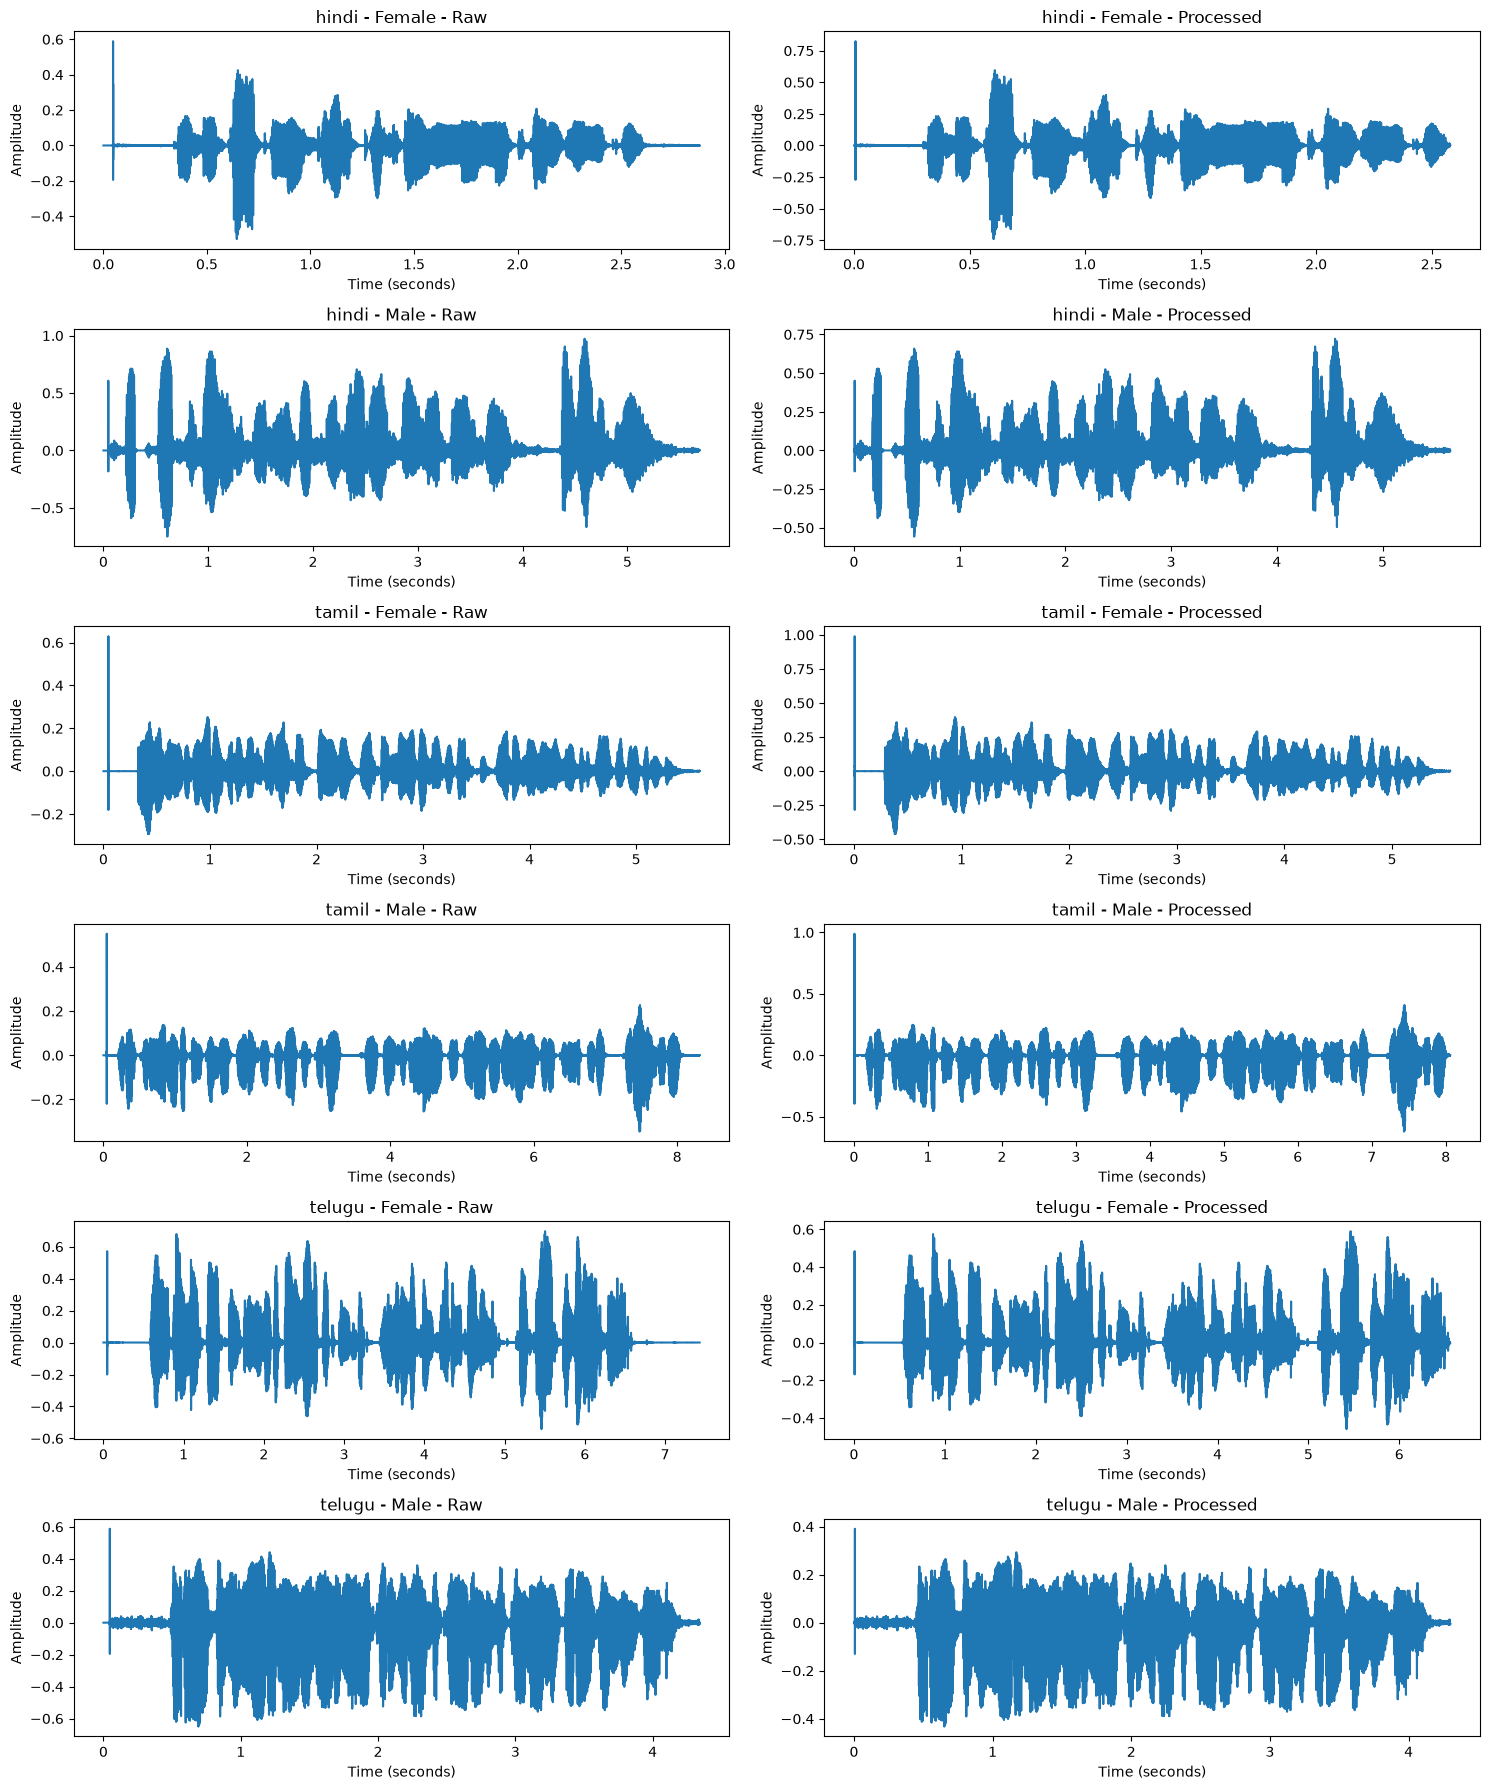

In [ ]:
# Select one successfully processed sample per language and gender
comparison_samples = []

for language in languages:
    for gender in sample_df["gender"].dropna().unique():

        matching_rows = sample_df[
            (sample_df["language"] == language) &
            (sample_df["gender"] == gender)
        ]

        if matching_rows.empty:
            continue

        selected_row = None
        selected_record = None

        for _, row in matching_rows.iterrows():
            expected_id = f"kathbath_{language}_{int(row['row_idx'])}"

            record = next(
                (r for r in processed_records if r["clip_id"] == expected_id),
                None
            )

            if record is not None:
                selected_row = row
                selected_record = record
                break

        if selected_record is not None:
            comparison_samples.append({
                "language": language,
                "gender": gender,
                "row": selected_row,
                "processed": selected_record
            })

# Load raw and processed audio for each selected sample
comparison_results = []

for sample in comparison_samples:

    row = sample["row"]
    processed_record = sample["processed"]
    language = sample["language"]

    record = datasets_no_decode[language][int(row["row_idx"])]
    audio_info = record["audio_filepath"]

    temp_path = None

    try:
        if audio_info.get("bytes") is not None:

            suffix = Path(str(row["fname"])).suffix or ".audio"

            with tempfile.NamedTemporaryFile(
                suffix=suffix, delete=False
            ) as temp_file:
                temp_path = Path(temp_file.name)
                temp_file.write(audio_info["bytes"])

            raw_path = temp_path

        elif audio_info.get("path") is not None:
            raw_path = Path(audio_info["path"])

        else:
            raise ValueError("Raw audio has neither bytes nor path")

        raw_audio, raw_sr = sf.read(
            str(raw_path),
            dtype="float32",
            always_2d=True
        )

    finally:
        if temp_path is not None:
            temp_path.unlink(missing_ok=True)

    processed_audio, processed_sr = sf.read(
        processed_record["path"],
        dtype="float32",
        always_2d=True
    )

    raw_mono = raw_audio.mean(axis=1)
    processed_mono = processed_audio.mean(axis=1)

    comparison_results.append({
        "language": language,
        "gender": sample["gender"],
        "raw": raw_mono,
        "processed": processed_mono,
        "raw_sr": raw_sr,
        "processed_sr": processed_sr,
        "raw_channels": raw_audio.shape[1],
        "processed_channels": processed_audio.shape[1]
    })

# Display comparison metrics
metrics = []

for result in comparison_results:

    raw = result["raw"]
    processed = result["processed"]

    metrics.append({
        "Language": result["language"],
        "Gender": result["gender"],
        "Raw Duration (s)": round(len(raw) / result["raw_sr"], 3),
        "Processed Duration (s)": round(
            len(processed) / result["processed_sr"], 3
        ),
        "Raw RMS": round(float(np.sqrt(np.mean(raw ** 2))), 4),
        "Processed RMS": round(
            float(np.sqrt(np.mean(processed ** 2))), 4
        ),
        "Raw Peak": round(float(np.max(np.abs(raw))), 4),
        "Processed Peak": round(
            float(np.max(np.abs(processed))), 4
        ),
        "Raw SR": result["raw_sr"],
        "Processed SR": result["processed_sr"],
        "Raw Channels": result["raw_channels"],
        "Processed Channels": result["processed_channels"]
    })

comparison_df = pd.DataFrame(metrics)
display(comparison_df)

# Plot raw vs processed waveforms
fig, axes = plt.subplots(
    len(comparison_results), 2,
    figsize=(15, 3 * len(comparison_results))
)

if len(comparison_results) == 1:
    axes = np.array([axes])

for i, result in enumerate(comparison_results):

    raw_time = np.arange(len(result["raw"])) / result["raw_sr"]
    processed_time = (
        np.arange(len(result["processed"])) / result["processed_sr"]
    )

    axes[i, 0].plot(raw_time, result["raw"])
    axes[i, 0].set_title(
        f"{result['language']} - {result['gender']} - Raw"
    )
    axes[i, 0].set_xlabel("Time (seconds)")
    axes[i, 0].set_ylabel("Amplitude")

    axes[i, 1].plot(processed_time, result["processed"])
    axes[i, 1].set_title(
        f"{result['language']} - {result['gender']} - Processed"
    )
    axes[i, 1].set_xlabel("Time (seconds)")
    axes[i, 1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

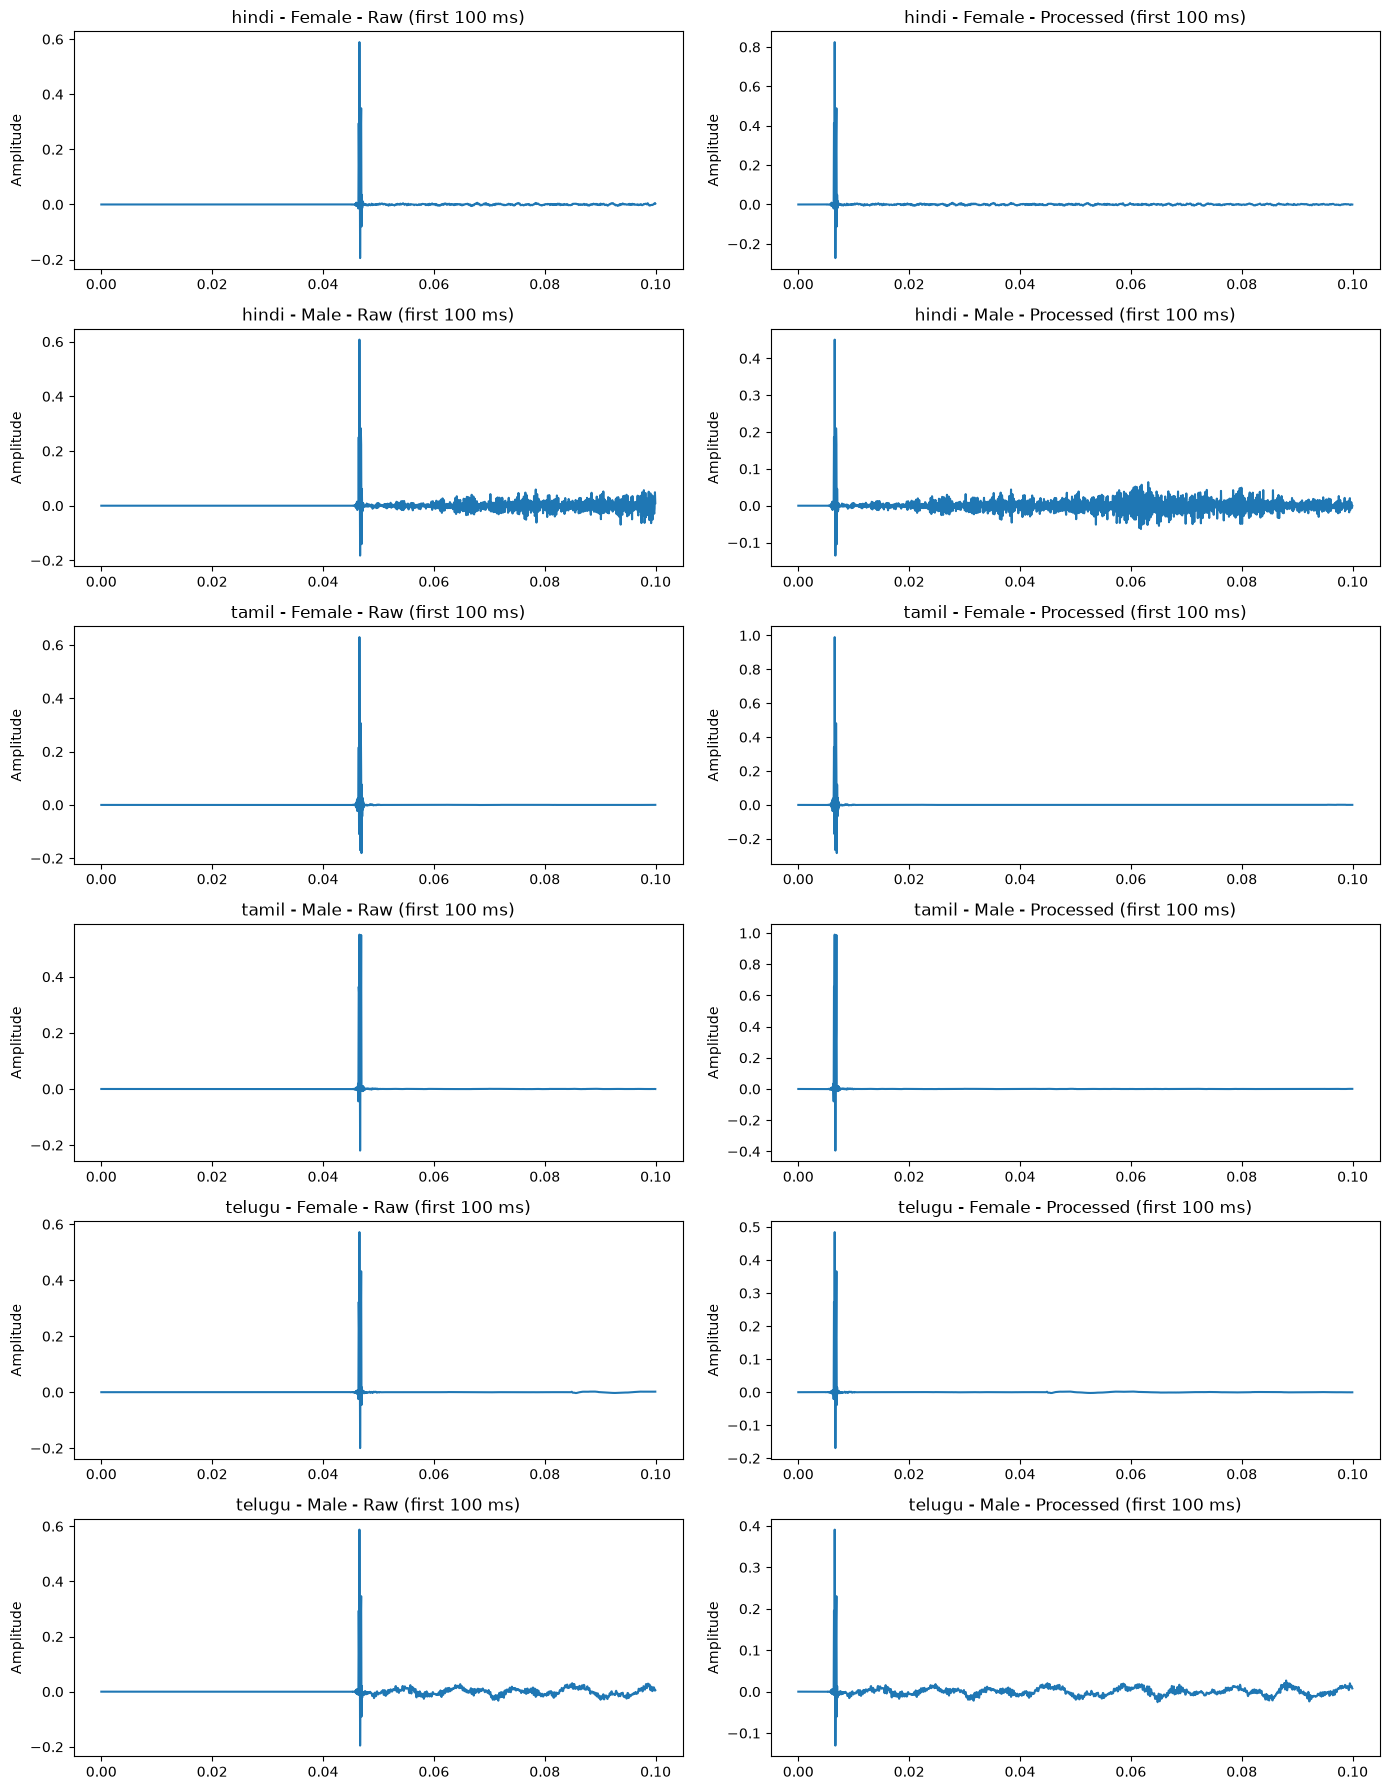

In [40]:
fig, axes = plt.subplots(
    len(comparison_results), 2,
    figsize=(14, 3 * len(comparison_results))
)

for i, result in enumerate(comparison_results):

    # Inspect the first 100 milliseconds
    raw = result["raw"]
    processed = result["processed"]

    raw_n = int(0.1 * result["raw_sr"])
    processed_n = int(0.1 * result["processed_sr"])

    raw_time = np.arange(raw_n) / result["raw_sr"]
    processed_time = np.arange(processed_n) / result["processed_sr"]

    axes[i, 0].plot(raw_time, raw[:raw_n])
    axes[i, 0].set_title(
        f"{result['language']} - {result['gender']} - Raw (first 100 ms)"
    )

    axes[i, 1].plot(processed_time, processed[:processed_n])
    axes[i, 1].set_title(
        f"{result['language']} - {result['gender']} - Processed (first 100 ms)"
    )

    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [41]:
transient_results = []

for result in comparison_results:

    for version in ["raw", "processed"]:

        audio = result[version]
        sr = result[f"{version}_sr"]

        # First 100 milliseconds
        first_100ms = audio[:int(0.1 * sr)]

        # Remaining audio
        remaining_audio = audio[int(0.1 * sr):]

        peak_index = np.argmax(np.abs(first_100ms))

        transient_results.append({
            "Language": result["language"],
            "Gender": result["gender"],
            "Version": version,
            "Peak Time (ms)": round(peak_index / sr * 1000, 2),
            "Peak Amplitude": round(
                float(np.max(np.abs(first_100ms))), 4
            ),
            "Remaining Audio Peak": round(
                float(np.max(np.abs(remaining_audio))), 4
            )
        })

transient_df = pd.DataFrame(transient_results)
display(transient_df)

,Language,Gender,Version,Peak Time (ms),Peak Amplitude,Remaining Audio Peak
0,hindi,Female,raw,46.56,0.5891,0.5292
1,hindi,Female,processed,6.56,0.8248,0.7409
2,hindi,Male,raw,46.56,0.6074,0.9727
3,hindi,Male,processed,6.56,0.4510,0.7222
4,tamil,Female,raw,46.56,0.6294,0.2934
5,tamil,Female,processed,6.56,0.9900,0.4615
6,tamil,Male,raw,46.56,0.5502,0.3456
7,tamil,Male,processed,6.56,0.9900,0.6218
8,telugu,Female,raw,46.56,0.5718,0.6965
9,telugu,Female,processed,6.56,0.4844,0.5901


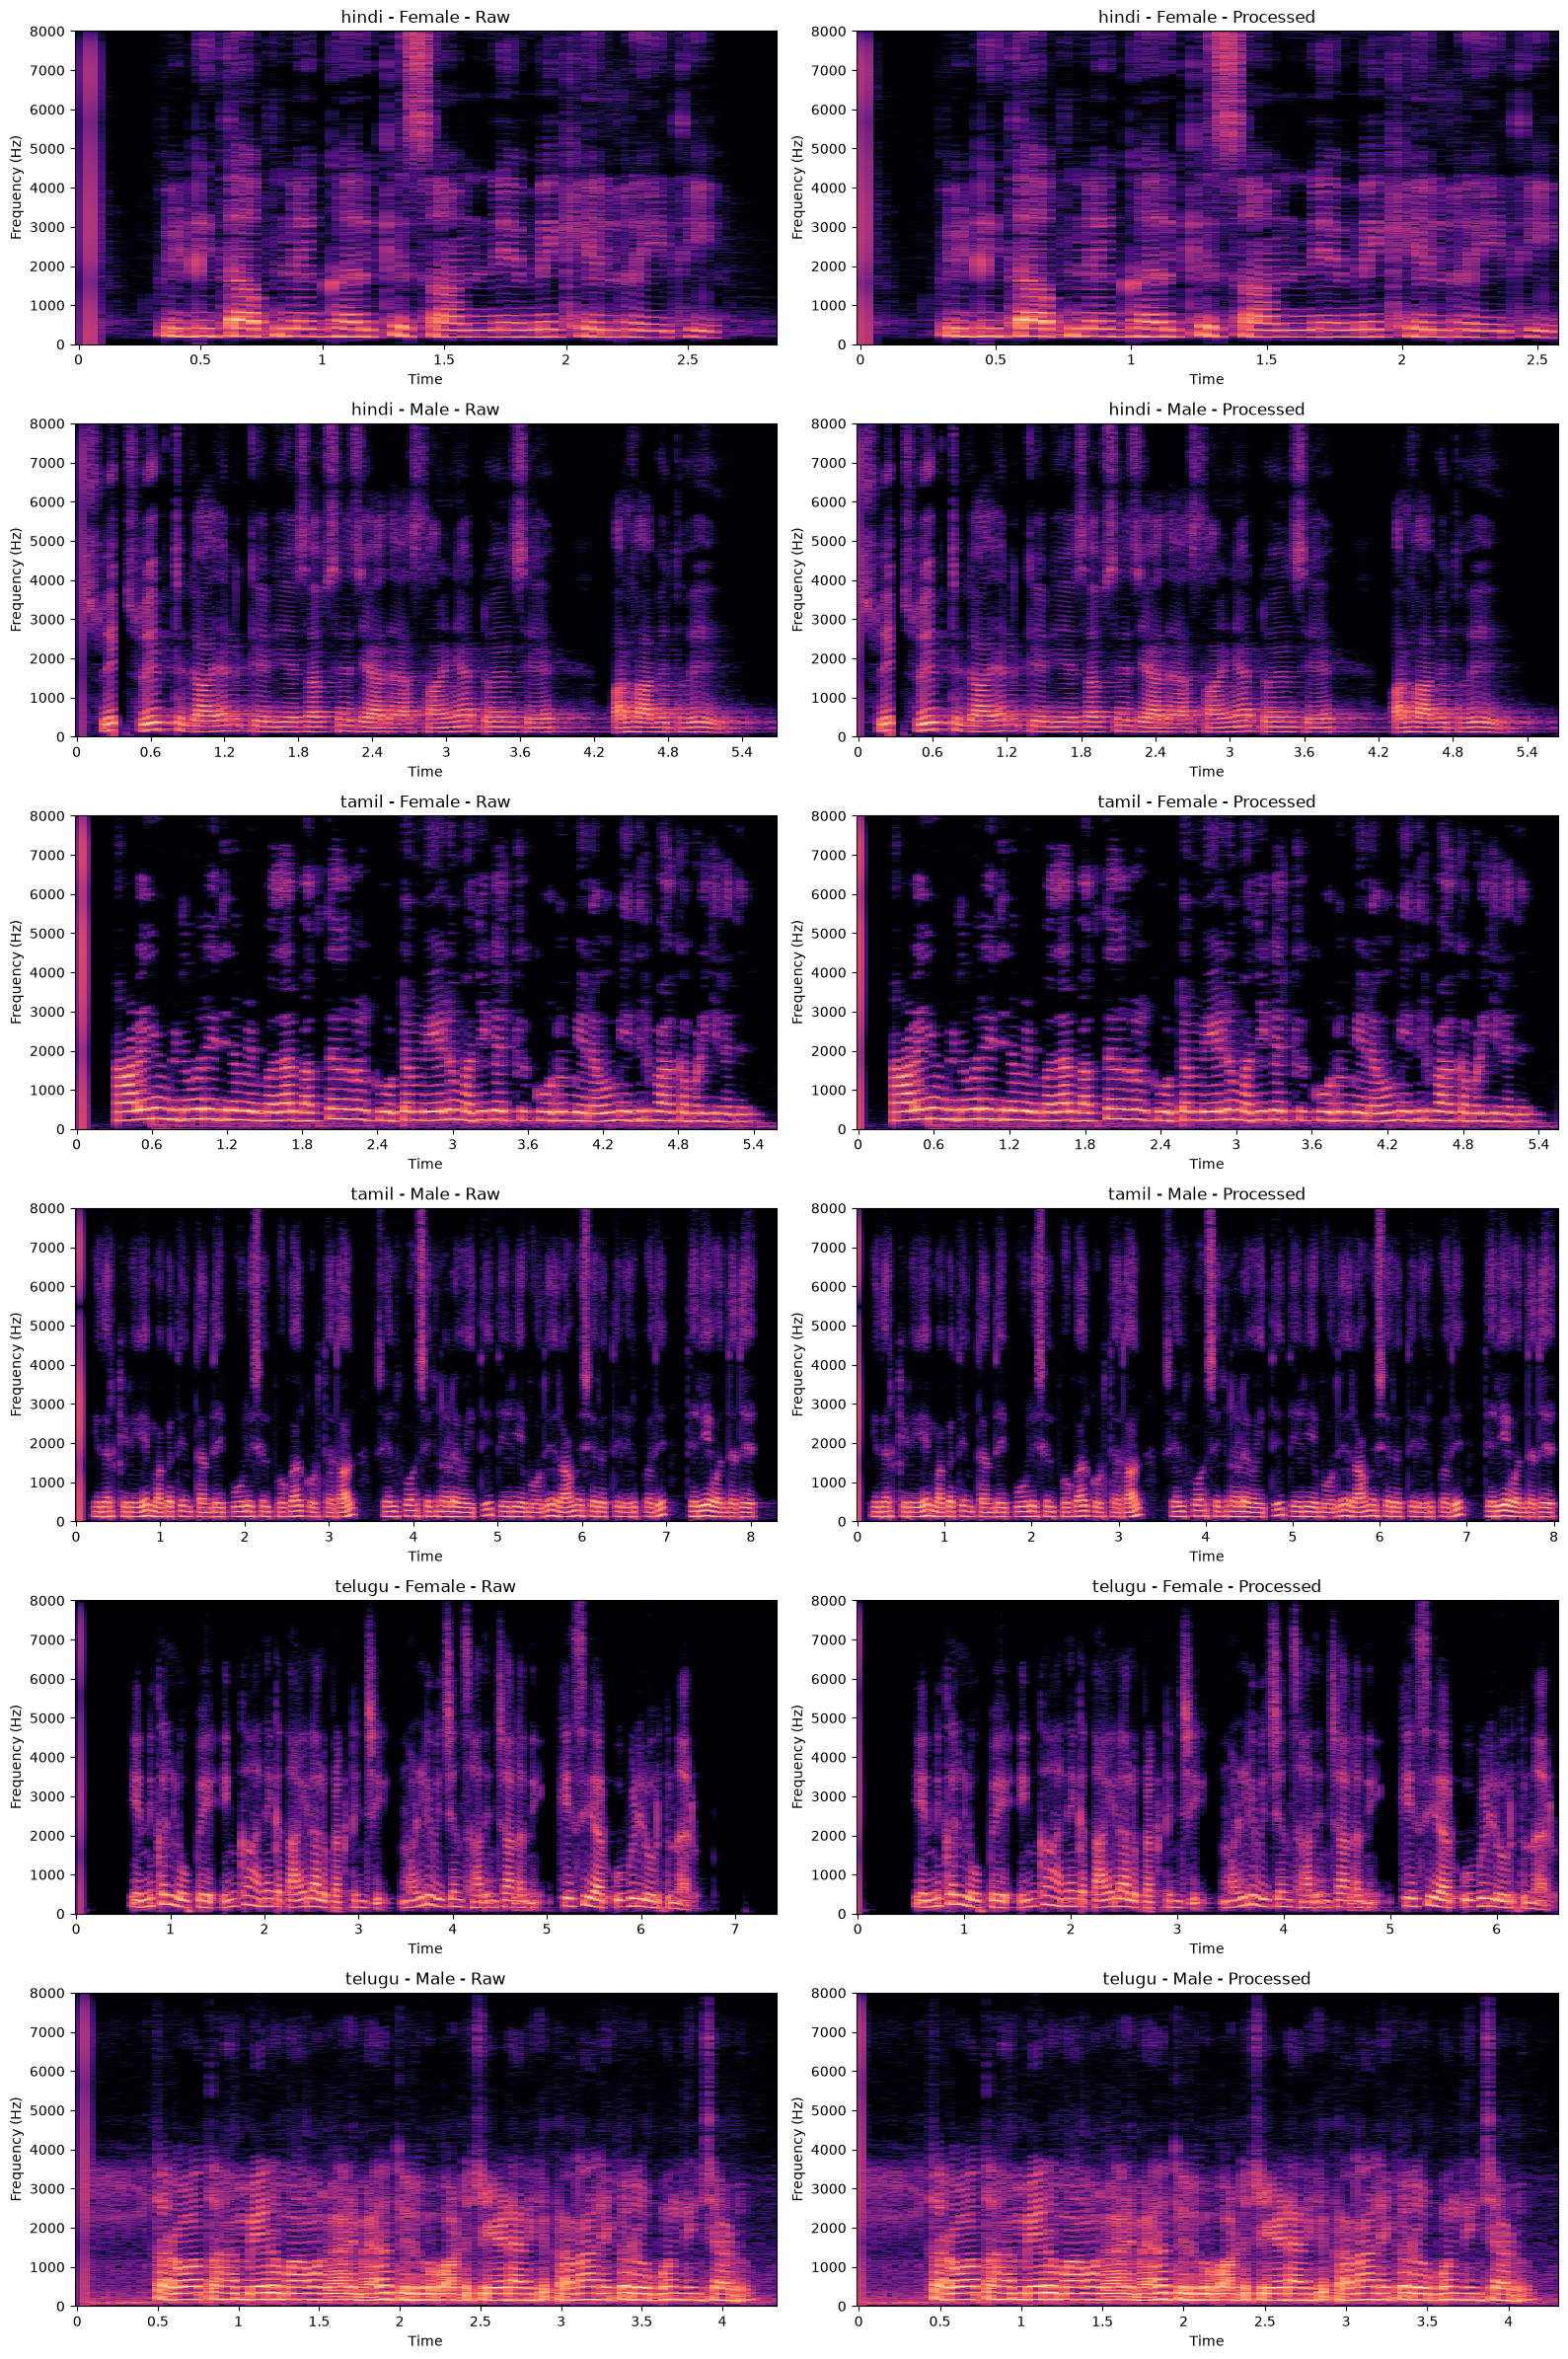

In [ ]:
fig, axes = plt.subplots(
    len(comparison_results), 2,
    figsize=(16, 4 * len(comparison_results))
)

for i, result in enumerate(comparison_results):

    # Raw audio spectrogram
    raw_spec = librosa.amplitude_to_db(
        np.abs(librosa.stft(result["raw"])),
        ref=np.max
    )

    librosa.display.specshow(
        raw_spec,
        sr=result["raw_sr"],
        hop_length=512,
        x_axis="time",
        y_axis="hz",
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(
        f"{result['language']} - {result['gender']} - Raw"
    )

    # Processed audio spectrogram
    processed_spec = librosa.amplitude_to_db(
        np.abs(librosa.stft(result["processed"])),
        ref=np.max
    )

    librosa.display.specshow(
        processed_spec,
        sr=result["processed_sr"],
        hop_length=512,
        x_axis="time",
        y_axis="hz",
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(
        f"{result['language']} - {result['gender']} - Processed"
    )

    axes[i, 0].set_ylabel("Frequency (Hz)")
    axes[i, 1].set_ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

In [ ]:
# Select 100 recordings, balanced across language and gender
groups = list(
    sample_df.groupby(["language", "gender"]).groups.keys()
)

quotas = {group: 16 for group in groups}
for group in groups[:4]:
    quotas[group] += 1

audit_parts = []

for group in groups:
    group_df = sample_df[
        (sample_df["language"] == group[0]) &
        (sample_df["gender"] == group[1])
    ]

    audit_parts.append(
        group_df.sample(
            n=quotas[group],
            random_state=42
        )
    )

audit_df = pd.concat(audit_parts).reset_index(drop=True)

assert len(audit_df) == 100

# Look up the corresponding processed audio files
processed_lookup = {
    record["clip_id"]: record["path"]
    for record in processed_records
}

audit_results = []

for _, row in audit_df.iterrows():

    language = row["language"]
    row_idx = int(row["row_idx"])
    clip_id = f"kathbath_{language}_{row_idx}"

    audio_info = datasets_no_decode[language][row_idx][
        "audio_filepath"
    ]

    audio_bytes = audio_info.get("bytes")
    audio_path = audio_info.get("path")
    temp_path = None

    if audio_bytes is not None:
        with tempfile.NamedTemporaryFile(
            suffix=".audio",
            delete=False
        ) as temp_file:
            temp_path = Path(temp_file.name)
            temp_file.write(audio_bytes)

        raw_path = temp_path

    elif audio_path is not None:
        raw_path = Path(audio_path)

    else:
        raise ValueError(f"No audio found for {clip_id}")

    try:
        raw_audio, raw_sr = sf.read(
            str(raw_path),
            dtype="float32",
            always_2d=True
        )
        raw_audio = raw_audio.mean(axis=1)

        processed_audio, processed_sr = sf.read(
            processed_lookup[clip_id],
            dtype="float32"
        )

    finally:
        if temp_path is not None:
            temp_path.unlink(missing_ok=True)

    # Inspect the first 100 milliseconds
    raw_window = raw_audio[:int(0.1 * raw_sr)]
    processed_window = processed_audio[
        :int(0.1 * processed_sr)
    ]

    raw_peak_idx = np.argmax(np.abs(raw_window))
    processed_peak_idx = np.argmax(np.abs(processed_window))

    audit_results.append({
        "clip_id": clip_id,
        "language": language,
        "gender": row["gender"],
        "raw_peak_ms": raw_peak_idx / raw_sr * 1000,
        "processed_peak_ms": processed_peak_idx / processed_sr * 1000,
        "raw_peak_amplitude": np.max(np.abs(raw_window)),
        "processed_peak_amplitude": np.max(
            np.abs(processed_window)
        )
    })

transient_audit_df = pd.DataFrame(audit_results)

print("Recordings audited:", len(transient_audit_df))

display(
    transient_audit_df.groupby(
        ["language", "gender"]
    ).agg(
        recordings=("clip_id", "count"),
        raw_mean_peak_ms=("raw_peak_ms", "mean"),
        processed_mean_peak_ms=("processed_peak_ms", "mean"),
        raw_median_peak_ms=("raw_peak_ms", "median"),
        processed_median_peak_ms=("processed_peak_ms", "median")
    ).round(2)
)

Recordings audited: 100


recordings  raw_mean_peak_ms  processed_mean_peak_ms  \
language gender                                                         
hindi    Female          17             46.71                    6.71   
         Male            17             46.65                   11.34   
tamil    Female          17             46.64                    6.64   
         Male            17             46.62                   11.89   
telugu   Female          16             46.60                    6.60   
         Male            16             46.64                    6.64   

                 raw_median_peak_ms  processed_median_peak_ms  
language gender                                                
hindi    Female               46.56                      6.56  
         Male                 46.56                      6.56  
tamil    Female               46.56                      6.56  
         Male                 46.56                      6.56  
telugu   Female               46.56                      6.56  
         Male                 46.56                      6.56